In [9]:
# packages and scripts
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import os
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from matplotlib import pyplot as plt

# scripts
import scripts.plotting as plot
import scripts.helper_functions as func


# load data
BASEDIR = os.path.expanduser('~/code/ast_mouse/')
data = pd.read_csv(BASEDIR + 'data/clean/clean_filtered_data.csv')

# animal lists
#retest_animals = ['AMA1-00613-retest','AMA1-00615-retest','AMA1-00616-retest','AMA1-00703']
#bad_mice = ['AMA2', 'AMA556', 'AMA426']

# remove retest mice for now
#data = data[~data['mouse'].isin(retest_animals)]
#data = data[~data['mouse'].isin(bad_mice)]

In [10]:
print(data.groupby('condition')['mouse'].nunique())

condition
GH             15
GH DREADDs      8
ISO            13
ISO DREADDs     6
Name: mouse, dtype: int64


In [11]:
# get tracectories and shift costs
trajectories, costs = func.calc_behavioural_metrics(data)
trajectories['block'] = pd.Categorical(trajectories['block'], categories=['SD', 'CD', 'IDS1', 'IDS2', 'IDS3', 'IDS4', 'EDS', 'EDSR'])

# get p switch after 1st win during each IDS
p_switch_means, p_switch_block, p_switch_diff = func.get_p_switch_after_correct(data, n_choices=5)

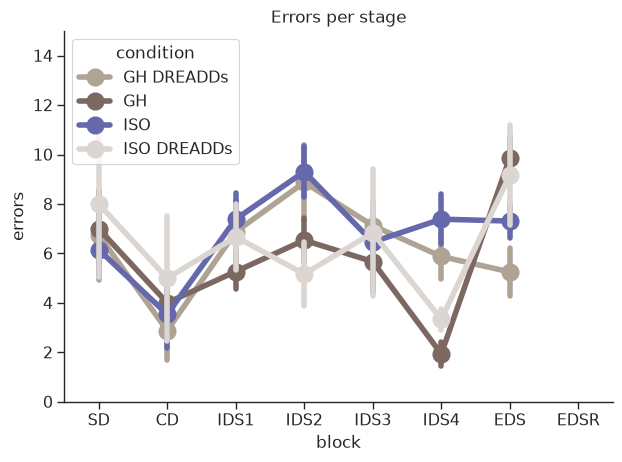

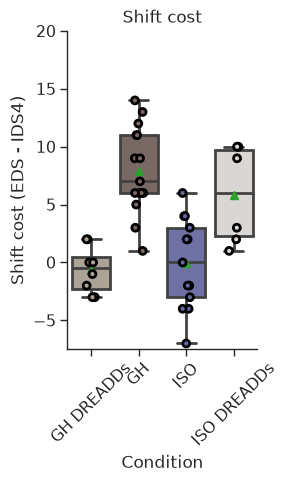

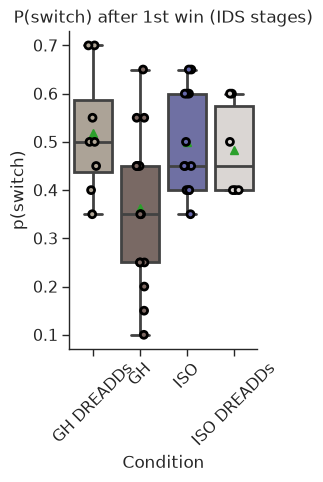

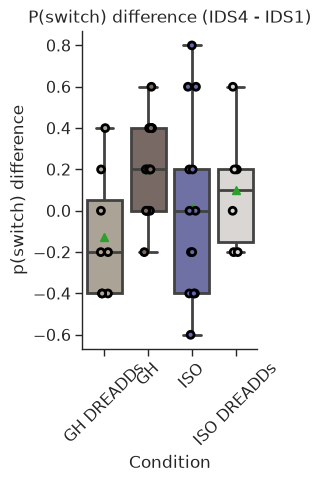

In [12]:
# function returns shift costs df so assign those
plot.group_level_plots(trajectories, costs, p_switch_means, p_switch_diff)

In [13]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd


# ANOVA analysis on shift costs
df = costs  # `.obj` gives you the original ungrouped DataFrame
lr_lm = ols('shift_cost ~ condition', data=df).fit()
table = sm.stats.anova_lm(lr_lm, typ=2) # Type 2 ANOVA DataFrame
print(table)

# now do post hoc test
tukey_oneway = pairwise_tukeyhsd(endog = df['shift_cost'], groups = df['condition'])
print(tukey_oneway.summary())

# get means
df = df.groupby('condition')
print(df['shift_cost'].mean())
print(df['shift_cost'].std())

               sum_sq    df          F        PR(>F)
condition  629.911447   3.0  16.003695  6.940044e-07
Residual   498.564744  38.0        NaN           NaN
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1      group2   meandiff p-adj   lower    upper  reject
--------------------------------------------------------------
        GH  GH DREADDs  -8.5583    0.0 -12.8185 -4.2982   True
        GH         ISO  -8.0103    0.0 -11.6976 -4.3229   True
        GH ISO DREADDs     -2.1 0.6305  -6.8005  2.6005  False
GH DREADDs         ISO   0.5481 0.9866  -3.8246  4.9207  False
GH DREADDs ISO DREADDs   6.4583 0.0108   1.2031 11.7136   True
       ISO ISO DREADDs   5.9103 0.0107   1.1076 10.7129   True
--------------------------------------------------------------
condition
GH             7.933333
GH DREADDs    -0.625000
ISO           -0.076923
ISO DREADDs    5.833333
Name: shift_cost, dtype: float64
condition
GH             3.750556
GH DREADDs     1.995531
ISO           

In [14]:
# ANOVA analysis on slope during general rule learning
df = costs  # `.obj` gives you the original ungrouped DataFrame
lr_lm = ols('slope ~ condition', data=df).fit()
table = sm.stats.anova_lm(lr_lm, typ=2) # Type 2 ANOVA DataFrame
print(table)

# now do post hoc test
tukey_oneway = pairwise_tukeyhsd(endog = df['slope'], groups = df['condition'])
print(tukey_oneway.summary())

# get means
df = df.groupby('condition')
print(df['slope'].mean())
print(df['slope'].std())

               sum_sq    df         F    PR(>F)
condition   96.476190   3.0  1.514915  0.226236
Residual   806.666667  38.0       NaN       NaN
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1      group2   meandiff p-adj   lower  upper  reject
------------------------------------------------------------
        GH  GH DREADDs  -2.3333 0.6572 -7.7522 3.0856  False
        GH         ISO  -3.3333 0.2413 -8.0236  1.357  False
        GH ISO DREADDs      0.0    1.0  -5.979  5.979  False
GH DREADDs         ISO     -1.0 0.9624  -6.562  4.562  False
GH DREADDs ISO DREADDs   2.3333 0.7848 -4.3514  9.018  False
       ISO ISO DREADDs   3.3333 0.4676 -2.7756 9.4423  False
------------------------------------------------------------
condition
GH             3.333333
GH DREADDs     1.000000
ISO            0.000000
ISO DREADDs    3.333333
Name: slope, dtype: float64
condition
GH             3.373567
GH DREADDs     4.535574
ISO            6.137318
ISO DREADDs    3.204164
Name: 

In [15]:
# let's just plot the individual behaviour
plot.individual_plots(trajectories, costs)

Text(0, 0.5, 'Incorrect choices % (excluding final 8 trials)')

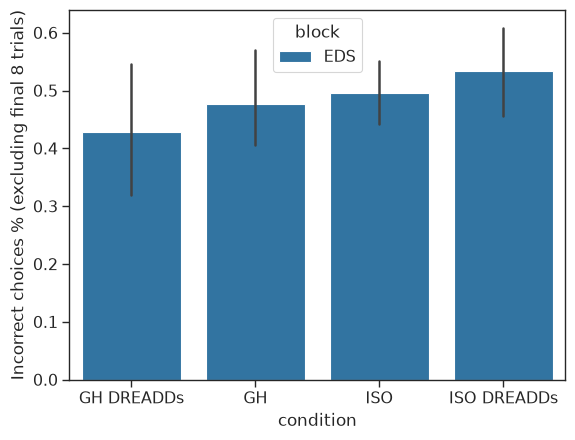

In [16]:
## let's analyse the distribution of errors in the EDS and EDSR for the different groups
blocks = ['EDS', 'EDSR']
tmp_df = data[['C', 'reward_loc','block', 'mouse', 'condition']].copy()
tmp_df['correct'] = (tmp_df['C'] == tmp_df['reward_loc']).astype(int)
tmp_df = tmp_df[tmp_df['block'].isin(blocks)]

tmp_df['trial_nr'] = tmp_df.groupby(['mouse', 'block']).cumcount()+1
tmp_df = tmp_df[tmp_df.groupby(['mouse', 'block'])['trial_nr'].transform('max') - tmp_df['trial_nr'] >= 8]
ratios = tmp_df.groupby(['mouse', 'block', 'condition'])['correct'].value_counts(normalize=True).unstack(fill_value=0).reset_index()

fig = sns.barplot(ratios, x='condition', y=0, hue='block')
fig.set_ylabel('Incorrect choices % (excluding final 8 trials)')
